# 🌱 Classify plant mortality using VI thresholds

In [8]:
import rasterio
from rasterio.mask import mask
import numpy as np
import geopandas as gpd

## 1. Extract vegetation index (VI) values from each mask

Vegetation indices can be extracted programmatically, as shown below.

Alternatively, this can be done in QGIS or ArcGIS using the **Zonal Statistics** tool. In this case, the NDVI (or the vegetation index you choose) must first be computed for the full raster using the **Raster Calculator**.

I noticed that small differences may appear between NDVI values computed per mask and those calculated directly from the full raster.


In [ ]:
# Methods to extract vegetation indices (VI) from segmentation masks

def extract_ndvi(nir, mred, nodata):
    # Shared valid mask
    valid = (
        (nir != nodata) &
        (mred != nodata) &
        np.isfinite(nir) &
        np.isfinite(mred)
    )

    if not np.any(valid):
        return {"mean": np.nan, "median": np.nan, "std": np.nan}

    ndvi = (nir[valid] - mred[valid]) / (nir[valid] + mred[valid] + 1e-10)

    return {
        "mean": np.nanmean(ndvi),
        "median": np.nanmedian(ndvi),
        "std": np.nanstd(ndvi)
    }

def extract_band_values_in_mask(mascara, band_idx):
    band_values = mascara[band_idx - 1].astype(np.float32)
    return band_values

def extract_vi_in_mask(raster, segment, band_names, nodata= 65535):
    for idx, mask_pred in segment.iterrows():
        mascara, _ =  mask(raster, shapes=[mask_pred.geometry], crop=True, nodata=band_names["nodata"])
        #green_values = extract_band_values_in_mask(mascara, band_names["green"])
        #red_values = extract_band_values_in_mask(mascara, band_names["red"])
        #blue_values = extract_band_values_in_mask(mascara, band_names["blue"])

        ### this are the bands from the multispectral sensor ###
        mred_values = extract_band_values_in_mask(mascara, band_names["mred"])
        #mgreen_values = extract_band_values_in_mask(mascara, band_names["mgreen"])
        nir_values = extract_band_values_in_mask(mascara, band_names["nir"])
        #re_values = extract_band_values_in_mask(mascara, band_names["re"])

        # compute VI
        ndvi_values = extract_ndvi(nir_values, mred_values, band_names["nodata"])

        if np.sum(mred_values) == 0 or np.sum(nir_values) == 0:
            print(f"Warning: No valid data in mask {mask_pred.name}")
            print(ndvi_values)

        segment.at[mask_pred.name, f"{"NDVI_mean"}"] = ndvi_values["mean"]
        segment.at[mask_pred.name, f"{"NDVI_median"}"] = ndvi_values["median"]
        segment.at[mask_pred.name, f"{"NDVI_std"}"] = ndvi_values["std"]

        print(f"Finished processing mask {mask_pred.name}") 
        
    return segment

In [ ]:
raster_path = "./mosaics_val/rosettes_gsd_1cm/rosettes_gsd_1cm_mosaic_multi.tif"
raster =  rasterio.open(raster_path)

raster.descriptions
# Make sure the band index set below matches the orders of the bands in the raster
band_names = {
    "red": 1,
    "green": 2,
    "blue": 3,
    "mgreen": 4,
    "mred": 5,
    "red_edge": 6,
    "nir": 7,
    "alpha": 8,
    "nodata": 65535
}

In [46]:
segmentation_masks_path = "./mosaics_val/rosettes_gsd_1cm/predictions/masks_sam_method1.gpkg"
segmentation_masks = gpd.read_file(segmentation_masks_path)

In [99]:
# make sure crs matches
print(raster.crs)
print(segmentation_masks.crs)

EPSG:32618
EPSG:32618


In [70]:
segmentation_masks_vi = extract_vi_in_mask(raster, segmentation_masks, band_names)

Finished processing mask 0
Finished processing mask 1
Finished processing mask 2
Finished processing mask 3
Finished processing mask 4
Finished processing mask 5
Finished processing mask 6
Finished processing mask 7
Finished processing mask 8
Finished processing mask 9
Finished processing mask 10
Finished processing mask 11
Finished processing mask 12
Finished processing mask 13
Finished processing mask 14
Finished processing mask 15
Finished processing mask 16
Finished processing mask 17
Finished processing mask 18
Finished processing mask 19
Finished processing mask 20
Finished processing mask 21
Finished processing mask 22
Finished processing mask 23
Finished processing mask 24
Finished processing mask 25
Finished processing mask 26
Finished processing mask 27
Finished processing mask 28
Finished processing mask 29
Finished processing mask 30
Finished processing mask 31
Finished processing mask 32
Finished processing mask 33
Finished processing mask 34
Finished processing mask 35
Fi

## 2. Estimate threshold and classify

We assume a bimodal distribution to the NDVI values extracted, and set a threshold at the intersection of the two.


In [ ]:
#segmentation_masks_vi.to_file("./mosaics_val/rosettes_gsd_1cm/predictions/masks_sam_method1_with_vi.gpkg")
# now lets plot 
#segmentation_masks_vi = gpd.read_file("./mosaics_val/rosettes_gsd_1cm/predictions/masks_sam_method1_with_vi.gpkg")

In [96]:
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import norm
from scipy.optimize import fsolve

def standarize(pred_df, column):
    """Standardize a vegetation index column."""
    scaler = StandardScaler()
    pred_df["NDVI_standard"] = scaler.fit_transform(pred_df[[column]])
    return pred_df, scaler


def deconvolution_hist(vi_values, vi_name="NDVI", xlim=None):
    """
    Fit a bimodal Gaussian Mixture Model (GMM) to vegetation index values,
    estimate a statistical threshold, and visualize the distribution.
    """
    # Reshape for sklearn
    vi_values = vi_values.reshape(-1, 1)

    # Assume bimodal distribution (e.g. alive vs dead)
    gmm = GaussianMixture(n_components=2, random_state=0)
    gmm.fit(vi_values)

    means = gmm.means_.flatten()
    stds = np.sqrt(gmm.covariances_).flatten()
    weights = gmm.weights_

    # Sort components by mean value
    idx = np.argsort(means)
    mean1, mean2 = means[idx]
    std1, std2 = stds[idx]
    w1, w2 = weights[idx]

    # Intersection between the two Gaussians (hard threshold)
    def intersection(x):
        return w1 * norm.pdf(x, mean1, std1) - w2 * norm.pdf(x, mean2, std2)

    threshold = fsolve(intersection, x0=(mean1 + mean2) / 2)[0]
    print("Statistical threshold:", threshold)

    # Fuzzy threshold: where posterior probabilities are similar
    def posterior(x):
        pdfs = [w * norm.pdf(x, mu, s) for w, mu, s in zip(weights, means, stds)]
        total = sum(pdfs)
        return [p / total for p in pdfs]

    xs = np.linspace(vi_values.min(), vi_values.max(), 1000)
    posteriors = np.array([posterior(x) for x in xs])
    diffs = np.abs(posteriors[:, 0] - posteriors[:, 1])

    ambiguous_band = xs[diffs < 0.1]
    band_min, band_max = ambiguous_band.min(), ambiguous_band.max()
    print("Threshold uncertainty band:", band_min, band_max)

    # Histogram
    sns.set(style="white", context="talk")
    plt.figure(figsize=(10, 6))
    sns.histplot(
        vi_values.flatten(),
        bins=100,
        color="#4c86b0",
        alpha=0.5,
        edgecolor="black",
        label=f"{vi_name} histogram"
    )

    plt.title(f"{vi_name} Histogram")
    plt.xlabel(vi_name)
    plt.ylabel("Individuals")
    if xlim:
        plt.xlim(xlim)
    plt.tight_layout()
    plt.show()

    # Histogram + GMM curves
    x = np.linspace(vi_values.min(), vi_values.max(), 1000)
    pdf1 = w1 * norm.pdf(x, mean1, std1)
    pdf2 = w2 * norm.pdf(x, mean2, std2)

    plt.figure(figsize=(10, 6))
    sns.histplot(
        vi_values.flatten(),
        bins=100,
        stat="density",
        color="#4c86b0",
        alpha=0.5,
        edgecolor="black"
    )
    plt.plot(x, pdf1, label="GMM component 1 (dead)", linewidth=2)
    plt.plot(x, pdf2, label="GMM component 2 (alive)", linewidth=2)
    plt.axvline(threshold, color="red", linestyle="--", label="Threshold")

    plt.axvspan(band_min, band_max, alpha=0.3, color="red", label="Confidence interval")
    plt.xlabel(vi_name)
    plt.ylabel("Density")
    plt.legend()
    if xlim:
        plt.xlim(xlim)
    plt.tight_layout()
    plt.show()

    return threshold, band_min, band_max


def calculo_mortalidad(segment_pred, vi_name, threshold):
    """Classify alive/dead using a vegetation index threshold."""
    segment_pred["alive"] = segment_pred[vi_name] >= threshold

    counts = segment_pred["alive"].value_counts()
    percentages = segment_pred["alive"].value_counts(normalize=True) * 100

    print(
        f"Dead: {counts.get(False, 0)} ({percentages.get(False, 0):.2f}%)\n"
        f"Alive: {counts.get(True, 0)} ({percentages.get(True, 0):.2f}%)\n"
        f"Total: {counts.sum()}"
    )

    return counts.get(True, 0), counts.get(False, 0), counts.sum()

<Figure size 640x480 with 0 Axes>

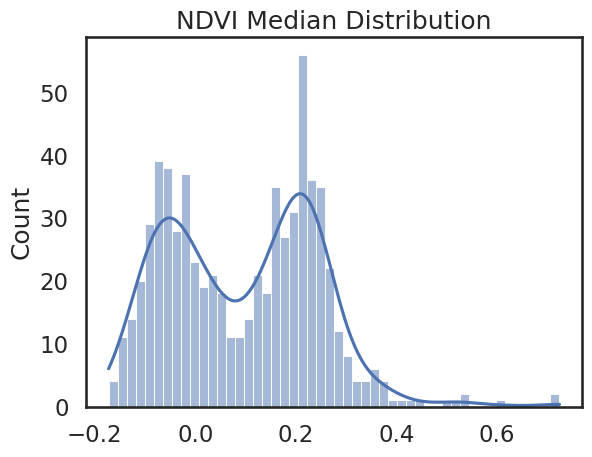

<Figure size 640x480 with 0 Axes>

In [93]:
sns.histplot(segmentation_masks_vi["NDVI_median"].dropna().values, bins=50, kde=True)
plt.title("NDVI Median Distribution")
plt.figure()

We clearle see a bimodal distribution, let's find a threshold to separate them

Statistical threshold: 0.03600671844863162
Threshold uncertainty band: 0.0322247 0.039408714


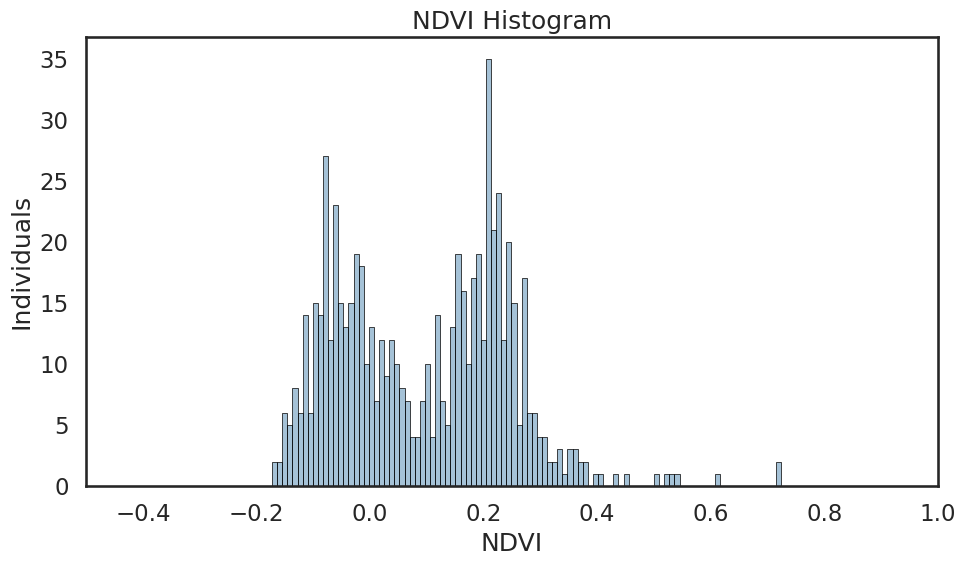

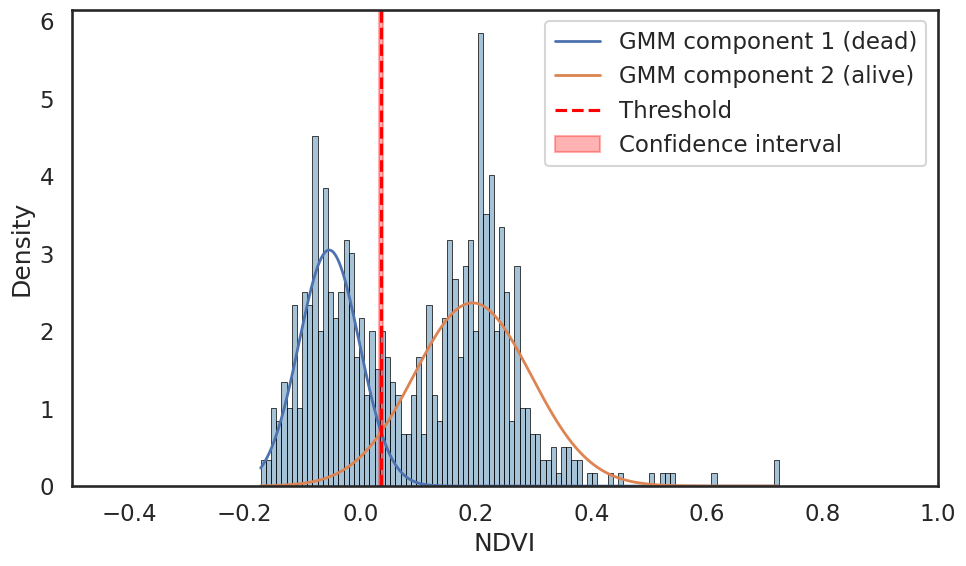

In [97]:
threshold, threshold_min, threshold_max = deconvolution_hist(segmentation_masks_vi["NDVI_median"].dropna().values, vi_name="NDVI", xlim=(-0.5, 1))

In [98]:
calculo_mortalidad(segmentation_masks_vi, "NDVI_median", threshold)

Dead: 274 (41.08%)
Alive: 393 (58.92%)
Total: 667


(np.int64(393), np.int64(274), np.int64(667))